<div style="background-color:#0A2A66; padding:25px; border-radius:6px; margin-bottom:24px; border-bottom:5px solid #F0A02E;">
  <h1 style="margin:0; font-size:30px; color:#FFFFFF;">Customer Value by Acquisition Channel</h1>
  <p style="margin:8px 0 0 0; font-size:17px; color:#D9E1F2;">Routledge Direct | Which channels bring customers worth having, how fast they pay back, and who CRM should talk to</p>
</div>

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">Context and objective</h2>

It is October 2025 and the FY2026 marketing budget is being put together. The Power BI report shows what each channel cost and what it returned on the day of the order. It cannot show what a customer goes on to be worth. A channel that wins cheap first orders from people who never return can look better on ROAS than one that brings in readers who buy every term, and a budget built on ROAS alone would fund the wrong one.

This notebook answers the third of the five questions in the README: which channels bring valuable customers, how fast does each earn back what it cost, and how should CRM win the second order? The answer ends in a unit economics table, one row per acquisition channel, which the FY2026 budget planner reads.

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">What this notebook covers</h2>

**Section 1: Setup.** Sign in, load three tables and reconcile each with the control totals from the SQL scripts.

**Section 2: Retention.** The share of customers who order again in each month after their first order, built on the full grid of cohort and month.

**Section 3: Repeat rate and twelve month value.** How many new customers order again within a year, and the gross profit each brings in over that year, by acquisition channel.

**Section 4: Acquisition cost, payback and break even.** Twelve month value against what each customer cost, the month that cost is earned back, and how much room each channel has.

**Section 5: Customers first acquired in a sale.** Whether people whose first order used a sale code are worth less, once the calendar and the channel are allowed for.

**Section 6: Lifecycle stages for CRM.** The RFM groups and four lifecycle stages already held on each customer, and how many people CRM can reach in each.

**Section 7: The unit economics table.** Everything the budget planner needs, one row per channel, written to BigQuery.

<h2 style="color:#0A2A66; border-left:5px solid #F0A02E; padding-left:12px; margin-top:28px;">Data used</h2>

| Table | Rows | What this notebook takes from it |
| --- | --- | --- |
| `ecomrl.clean.customer_value` | 58,101 | One row per person: first order, acquisition channel, twelve month value, sale group, RFM scores and lifecycle stage. Built by `05_customer_value.sql` |
| `ecomrl.clean.orders` | 75,918, read as monthly activity | People ordering and gross profit by cohort, acquisition channel and month since the first order |
| `ecomrl.clean.channel_daily` | 34,356, read as 26 | Ad spend, affiliate commission and new customers by channel, split at 30 September 2024 |

Three definitions hold all the way through, the same ones the SQL scripts use:

- **Twelve month value** is gross profit in the 365 days after each person's own first order, averaged only over the 36,569 customers whose first order was on or before 30 September 2024. Anyone newer has not had a full year to come back, so they are left out of every twelve month figure rather than allowed to drag it down.
- **Retention is built on the full grid** of cohort, channel and month, so a month in which nobody from a cohort ordered still counts its people as eligible.
- **Repeat rate** is the share of those mature customers who order again within twelve months: 19.6 percent overall.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 1: Setup</h2>

**Step 1.1: Libraries, sign in and chart style**

The notebook runs in Google Colab against the BigQuery sandbox, signed in with the Google account that owns the `ecomrl` project. `authenticate_user()` opens a Google sign in window the first time it runs. The helpers at the bottom keep later cells short: `check()` prints a result next to its control total and says whether they agree, `show()` formats a table and leaves missing values blank, and `hbar()` draws the ranked bar charts.

In [1]:
# 1. Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.contingency_tables import StratifiedTable
from IPython.display import display
from google.colab import auth
from google.cloud import bigquery

# 2. Sign in to Google and connect to the Routledge BigQuery project
auth.authenticate_user()
client = bigquery.Client(project='ecomrl')

def q(sql):
    """Run a query against BigQuery and return a dataframe."""
    return client.query(sql).to_dataframe()

# 3. Colours, taken from the Taylor & Francis brand
NAVY, AMBER, GREY = '#0A2A66', '#F0A02E', '#808080'
BLUE, OLIVE = '#1C86D8', '#8A7A10'
FAMILY_COLOURS = {'Google': NAVY, 'Meta': OLIVE,
                  'Affiliate': BLUE, 'Owned and organic': GREY}

# 4. Chart defaults, so every chart starts from the same look
plt.rcParams.update({
    'font.family'        : 'sans-serif',
    'font.sans-serif'    : ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'axes.spines.top'    : False,
    'axes.spines.right'  : False,
    'axes.edgecolor'     : GREY,
    'axes.titleweight'   : 'bold',
    'axes.titlesize'     : 13,
    'axes.titlecolor'    : NAVY,
    'axes.labelcolor'    : '#1F2430',
    'axes.prop_cycle'    : plt.cycler(color=[NAVY, BLUE, OLIVE, AMBER, GREY]),
    'figure.figsize'     : (11, 6),
    'figure.dpi'         : 110,
})

# 5. Display names and families, the same ones the dashboard uses
LABEL = {
    'google_brand'        : 'Google Brand',
    'google_nonbrand'     : 'Google Non Brand',
    'google_shopping'     : 'Google Shopping',
    'google_paid_untagged': 'Google Paid Untagged',
    'meta_prospecting'    : 'Meta Prospecting',
    'meta_retargeting'    : 'Meta Retargeting',
    'meta_untagged'       : 'Meta Untagged',
    'affiliate_coupon'    : 'Affiliate Coupon',
    'affiliate_content'   : 'Affiliate Content',
    'email'               : 'Email',
    'organic_search'      : 'Organic Search',
    'direct'              : 'Direct',
    'referral'            : 'Referral',
}
FAMILY = {ch: ('Google' if ch.startswith('google') else
               'Meta' if ch.startswith('meta') else
               'Affiliate' if ch.startswith('affiliate') else
               'Owned and organic') for ch in LABEL}
COLOUR_BY_LABEL = {LABEL[ch]: FAMILY_COLOURS[FAMILY[ch]] for ch in LABEL}

# 6. Helpers
def check(label, got, sql_value, fmt='{:,.0f}', dp=0):
    """Print a result beside its control total and say whether they agree."""
    status = 'matches' if round(float(got), dp) == round(float(sql_value), dp) else 'check'
    print(f'{label:<48}{fmt.format(got):>16}{fmt.format(sql_value):>16}   {status}')

def show(df, money=(), pct=(), pct2=(), ints=(), dec=()):
    """Display a formatted copy of a table. Missing means not applicable, so it shows blank, never zero."""
    out = df.copy()
    rules = [(money, '${:,.2f}'), (pct, '{:.1f}%'), (pct2, '{:.2f}%'),
             (ints, '{:,.0f}'), (dec, '{:.2f}')]
    for cols, f in rules:
        for c in cols:
            # adding 0.0 turns -0.0 into 0.0; the minus sign goes in front of a dollar sign
            out[c] = out[c].map(lambda v: '' if pd.isna(v) else
                                ('-' + f.format(-(v + 0.0)) if v + 0.0 < 0 and f.startswith('$') else f.format(v + 0.0)))
    display(out)

def hbar(values, fmt, title, xlabel, colours=None, err=None, ref=None, ref_label='', axis_fmt=None, legend=None):
    """Ranked horizontal bars, biggest at the top, value labels, optional error bars."""
    values = values.sort_values()
    colours = colours or COLOUR_BY_LABEL
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(values) + 2))
    xerr = None if err is None else err.reindex(values.index).T.values
    ax.barh(values.index, values.values, color=[colours[i] for i in values.index],
            xerr=xerr, error_kw={'ecolor': GREY, 'capsize': 3, 'linewidth': 1})
    reach = values.values + (0 if err is None else err.reindex(values.index)['hi'].values)
    pad = reach.max() * 0.01
    for i, (v, r) in enumerate(zip(values.values, reach)):
        ax.text(r + pad, i, fmt(v), va='center', fontsize=9, color='#1F2430')
    if ref is not None:
        ax.axvline(ref, color=GREY, linestyle='--', linewidth=1.2)
        ax.text(ref, len(values) - 0.45, f' {ref_label}', color=GREY, fontsize=9, va='bottom')
    ax.set_xlim(0, reach.max() * 1.15)
    ax.set_xlabel(xlabel)
    if axis_fmt:
        ax.xaxis.set_major_formatter(mtick.StrMethodFormatter(axis_fmt))
    ax.set_title(title, loc='left')
    ax.grid(axis='x', color='#E0E0E0')
    ax.set_axisbelow(True)
    if (colours is COLOUR_BY_LABEL) if legend is None else legend:
        families = [f for f in FAMILY_COLOURS if FAMILY_COLOURS[f] in set(colours[i] for i in values.index)]
        ax.legend(handles=[Patch(color=FAMILY_COLOURS[f], label=f) for f in families],
                  frameon=False, loc='lower right')
    plt.tight_layout()
    plt.show()

def fmt_p(p):
    """p-values to three significant figures, so very small ones stay readable."""
    return 'below 1e-300' if p < 1e-300 else f'{p:.3g}'

def signed_usd(v):
    """A dollar gap with its sign in front: +$5.30 or -$5.30."""
    return f"{'+' if v >= 0 else '-'}${abs(v):,.2f}"

print('Connected to', client.project)

Connected to ecomrl


**Step 1.2: Load the three tables and check them**

`customer_value` comes in whole, because every later section slices people a different way and 58,101 rows sit easily in memory. Orders are summed in BigQuery to one row per cohort month, acquisition channel and month since the first order, for months 0 to 12; a month in which nobody from a cohort ordered has no row, and Section 2 fills the gaps. `channel_daily` is summed to one row per channel and per side of 30 September 2024, where the mature window ends.

Each line prints a figure next to its control total from the checks in `03_clean_layer.sql`, `04_reporting_tables.sql` and `05_customer_value.sql`, and says whether the two match.

In [2]:
# 1. One row per person, built by 05_customer_value.sql
cv = q("select * from `ecomrl.clean.customer_value`")
cv['first_order_date'] = pd.to_datetime(cv['first_order_date'])
cv['cohort_month']     = pd.to_datetime(cv['cohort_month'])
for col in cv.columns:
    if str(cv[col].dtype) in ('boolean', 'bool'):
        cv[col] = cv[col].astype(bool)

# 2. Monthly activity: people ordering and gross profit, by cohort, channel and month since the first order
act = q("""
    select
      cv.cohort_month,
      cv.acquisition_channel,
      date_diff(o.order_month, cv.cohort_month, month) as month_index,
      count(distinct o.person_id)                      as active_customers,
      sum(o.gross_profit_usd)                          as gross_profit_usd
    from `ecomrl.clean.orders` o
    join `ecomrl.clean.customer_value` cv on cv.person_id = o.person_id
    where date_diff(o.order_month, cv.cohort_month, month) between 0 and 12
    group by cv.cohort_month, cv.acquisition_channel, date_diff(o.order_month, cv.cohort_month, month)
""")
act['cohort_month'] = pd.to_datetime(act['cohort_month'])
act['month_index']  = act['month_index'].astype(int)
act[['active_customers', 'gross_profit_usd']] = act[['active_customers', 'gross_profit_usd']].astype(float)

# 3. Cost and new customers per channel, either side of the end of the mature window
cost = q("""
    select
      channel,
      date <= date '2024-09-30'     as in_mature_window,
      sum(spend_usd)                as spend_usd,
      sum(affiliate_commission_usd) as affiliate_commission_usd,
      sum(new_customers)            as new_customers
    from `ecomrl.clean.channel_daily`
    group by channel, in_mature_window
""")
cost['in_mature_window'] = cost['in_mature_window'].astype(bool)
cost[['spend_usd', 'affiliate_commission_usd', 'new_customers']] = \
    cost[['spend_usd', 'affiliate_commission_usd', 'new_customers']].astype(float)

# 4. Mature customers: first order on or before 30 September 2024, so a full year behind them
mature = cv[cv['has_full_12m']].copy()

# 5. Reconcile with the control totals
print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('customer_value rows',                     len(cv),                                     58101)
check('mature customers',                        len(mature),                                 36569)
check('mature customers ordering again in 12m',  mature['repeated_within_12m'].sum(),         7175)
check('orders',                                  cv['orders'].sum(),                          75918)
check('net revenue after refunds',               cv['revenue_usd'].sum(),                     11907875.43, '${:,.2f}', 2)
check('gross profit',                            cv['gross_profit_usd'].sum(),                7421060.08,  '${:,.2f}', 2)
check('people active in month 0',                act.loc[act.month_index == 0, 'active_customers'].sum(), 58101)
check('ad spend, channel_daily',                 cost['spend_usd'].sum(),                     1247288.94,  '${:,.2f}', 2)
check('affiliate commission, channel_daily',     cost['affiliate_commission_usd'].sum(),      227336.14,   '${:,.2f}', 2)
check('new customers, channel_daily',            cost['new_customers'].sum(),                 58101)
check('new customers to 30 Sep 2024',            cost.loc[cost.in_mature_window, 'new_customers'].sum(), 36569)
print(f'\nmonthly activity rows: {len(act):,}')
print(f'cost rows: {len(cost)} (13 channels, two windows each)')

                                                   this notebook        from SQL
customer_value rows                                       58,101          58,101   matches
mature customers                                          36,569          36,569   matches
mature customers ordering again in 12m                     7,175           7,175   matches
orders                                                    75,918          75,918   matches
net revenue after refunds                         $11,907,875.43  $11,907,875.43   matches
gross profit                                       $7,421,060.08   $7,421,060.08   matches
people active in month 0                                  58,101          58,101   matches
ad spend, channel_daily                            $1,247,288.94   $1,247,288.94   matches
affiliate commission, channel_daily                  $227,336.14     $227,336.14   matches
new customers, channel_daily                              58,101          58,101   matches
new custo

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 2: Retention</h2>

**Step 2.1: Who orders again, month by month**

Every cohort and acquisition channel is crossed with months 0 to 12, keeping only the months it has lived through (September 2025 is the last month in the data). Activity is joined on afterwards and a missing row becomes zero. Building the grid first matters: reading activity straight off would drop quiet months from the denominator as well as the numerator, and retention would come out too high.

The overall curve is checked against `05_customer_value.sql`: month 1 at 0.63 percent (347 active of 55,195 eligible), month 12 at 2.14 percent (784 of 36,569), and the peak in month 8. Month 12's eligible count being exactly the mature customer count is the proof that the denominator is right. Month 0 is left off the chart, because everyone is active in the month they first bought.

                                                   this notebook        from SQL
month 1 eligible                                          55,195          55,195   matches
month 1 active                                               347             347   matches
month 1 retention                                          0.63%           0.63%   matches
month 12 eligible                                         36,569          36,569   matches
month 12 active                                              784             784   matches
month 12 retention                                         2.14%           2.14%   matches
peak month                                                     8               8   matches


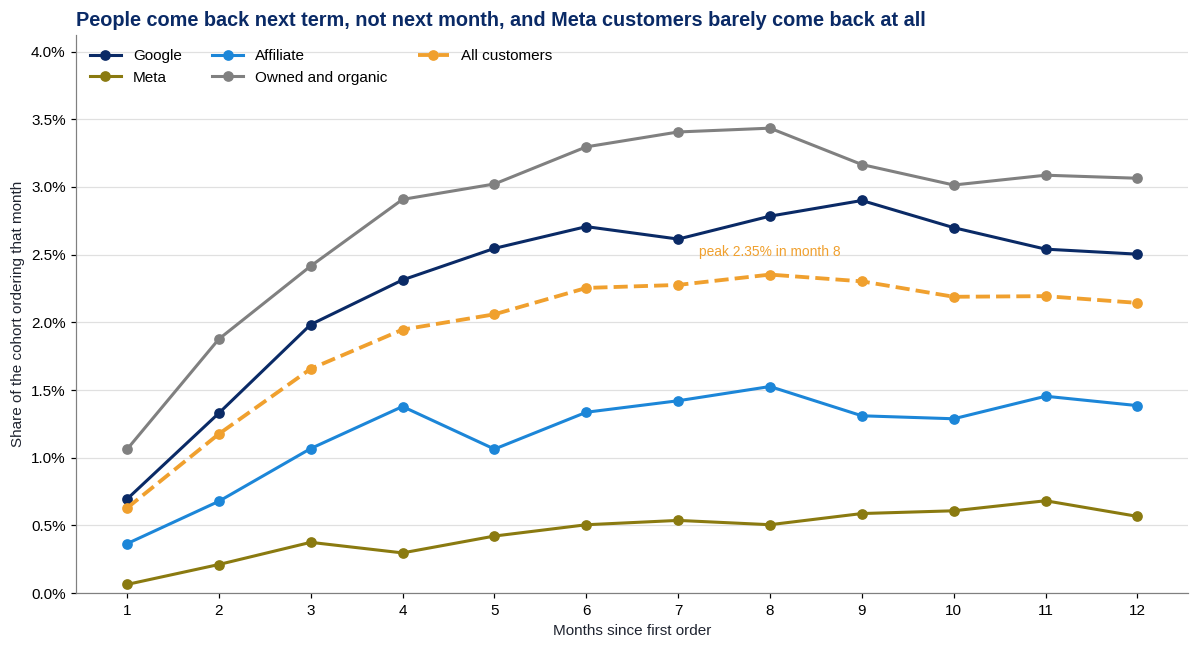

,month 1,month 4,month 8,month 12,months 1 to 12
acquisition_channel,,,,,
Referral,1.05%,3.05%,3.86%,3.34%,3.10%
Organic Search,1.20%,3.09%,3.78%,3.23%,2.91%
Direct,1.03%,3.05%,3.00%,2.96%,2.66%
Google Non Brand,0.84%,2.50%,3.29%,2.85%,2.59%
Google Brand,0.82%,2.76%,2.96%,2.82%,2.56%
Affiliate Content,0.88%,2.70%,3.10%,2.97%,2.49%
Google Paid Untagged,1.32%,2.62%,3.34%,2.30%,2.26%
Email,0.53%,1.69%,2.18%,2.23%,1.91%
Google Shopping,0.29%,1.54%,1.67%,1.55%,1.34%


In [3]:
# 1. Cohort sizes from the people themselves, so a cohort nobody came back from still counts
sizes = (cv.groupby(['cohort_month', 'acquisition_channel'])
           .size().rename('cohort_size').reset_index())

# 2. Every cohort against months 0 to 12, keeping only months that have happened
grid = sizes.merge(pd.DataFrame({'month_index': range(13)}), how='cross')
months_lived = (2025 - grid['cohort_month'].dt.year) * 12 + (9 - grid['cohort_month'].dt.month)
grid = grid[grid['month_index'] <= months_lived].copy()

# 3. Join the activity on. No row means nobody ordered: zero, not missing
grid = grid.merge(act, on=['cohort_month', 'acquisition_channel', 'month_index'], how='left')
grid[['active_customers', 'gross_profit_usd']] = grid[['active_customers', 'gross_profit_usd']].fillna(0)
grid['family'] = grid['acquisition_channel'].map(FAMILY)

def rates(by):
    """Active over eligible, summed first and divided once, never an average of rates."""
    r = grid.groupby(by).agg(active=('active_customers', 'sum'), eligible=('cohort_size', 'sum'))
    r['active_pct'] = 100 * r['active'] / r['eligible']
    return r

curve = rates('month_index')
fam   = rates(['family', 'month_index'])['active_pct'].unstack(0)

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('month 1 eligible',   curve.loc[1, 'eligible'],    55195)
check('month 1 active',     curve.loc[1, 'active'],      347)
check('month 1 retention',  curve.loc[1, 'active_pct'],  0.63, '{:.2f}%', 2)
check('month 12 eligible',  curve.loc[12, 'eligible'],   36569)
check('month 12 active',    curve.loc[12, 'active'],     784)
check('month 12 retention', curve.loc[12, 'active_pct'], 2.14, '{:.2f}%', 2)
check('peak month',         curve.loc[1:, 'active_pct'].idxmax(), 8)

# 4. The overall curve with each channel family beside it
fig, ax = plt.subplots()
m = range(1, 13)
for f, colour in FAMILY_COLOURS.items():
    ax.plot(m, fam.loc[1:12, f], color=colour, marker='o', linewidth=2, label=f)
ax.plot(m, curve.loc[1:12, 'active_pct'], color=AMBER, linewidth=2.5, linestyle='--', marker='o', label='All customers')
peak = curve.loc[1:12, 'active_pct'].idxmax()
ax.annotate(f"peak {curve.loc[peak, 'active_pct']:.2f}% in month {peak}", (peak, curve.loc[peak, 'active_pct']),
            textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9, color=AMBER)
ax.set_xticks(list(m))
ax.set_xlabel('Months since first order')
ax.set_ylabel('Share of the cohort ordering that month')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_ylim(0, fam.loc[1:12].values.max() * 1.2)
ax.grid(axis='y', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc='upper left')
ax.set_title('People come back next term, not next month, and Meta customers barely come back at all', loc='left')
plt.tight_layout()
plt.show()

# 5. Every channel at four points, plus the average share active across months 1 to 12
ch = rates(['acquisition_channel', 'month_index'])
by_channel = ch['active_pct'].unstack()[[1, 4, 8, 12]]
by_channel.columns = ['month 1', 'month 4', 'month 8', 'month 12']
later = ch.loc[(slice(None), slice(1, 12)), :].groupby(level=0)[['active', 'eligible']].sum()
by_channel['months 1 to 12'] = 100 * later['active'] / later['eligible']
by_channel.index = by_channel.index.map(LABEL)
show(by_channel.sort_values('months 1 to 12', ascending=False), pct2=list(by_channel.columns))

**Insight and business takeaway:**

The month straight after a first order is the quietest of the year: 0.63 percent of customers order again. The share then climbs to 2.35 percent in month 8 and eases to 2.14 percent by month 12. That is the academic calendar showing through. Someone who buys for the autumn term comes back for the next term, not four weeks later.

The families sit far apart. Owned and organic customers return most and Meta customers least. In an average month between months 1 and 12, 0.37 percent of a Meta Prospecting cohort orders, against 3.10 percent for Referral and 2.91 percent for Organic Search. Only Affiliate Coupon is lower, at 0.21 percent, while Affiliate Content runs at 2.49 percent, close to Google Brand's 2.56.

**Indication:** CRM should time its second contact to the term calendar. An email a month after the first order lands in the quietest month; the same email in the weeks before the next term lands when people are most likely to buy. Meta and coupon customers are where a second order would be new behaviour, so a post purchase programme has the most to prove there, measured against a holdout group.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 3: Repeat Rate and Twelve Month Value</h2>

**Step 3.1: Repeat rate by acquisition channel**

Repeat rate follows the definition in the README: the share of new customers who order again within twelve months of their first order, on the 36,569 mature customers only. Each rate gets a 95 percent Wilson interval, which behaves well at small counts and at rates near zero. A chi-square test then asks whether repeat rate depends on channel at all, and each channel is marked above or below the overall rate only when its whole interval sits on one side of it.

`05_customer_value.sql` gave 19.6 percent overall (7,175 of 36,569), with Referral highest at 29.8 percent and Affiliate Coupon lowest at 2.5.

                                                   this notebook        from SQL
overall repeat rate                                        19.6%           19.6%   matches
Referral repeat rate                                       29.8%           29.8%   matches
Affiliate Coupon repeat                                     2.5%            2.5%   matches

Chi-square 2,406.2 on 12 degrees of freedom, p = below 1e-300
against_overall
above, beyond noise           6
below, beyond noise           5
not different from overall    2


,customers,repeaters,repeat_pct,ci_low_pct,ci_high_pct,against_overall
acquisition_channel,,,,,,
Referral,"1,407",419,29.8%,27.4%,32.2%,"above, beyond noise"
Organic Search,"6,418","1,855",28.9%,27.8%,30.0%,"above, beyond noise"
Direct,"2,470",657,26.6%,24.9%,28.4%,"above, beyond noise"
Google Non Brand,"6,204","1,650",26.6%,25.5%,27.7%,"above, beyond noise"
Google Brand,"3,187",844,26.5%,25.0%,28.0%,"above, beyond noise"
Affiliate Content,"1,749",463,26.5%,24.5%,28.6%,"above, beyond noise"
Google Paid Untagged,261,60,23.0%,18.3%,28.5%,not different from overall
Email,"1,388",282,20.3%,18.3%,22.5%,not different from overall
Google Shopping,"3,289",491,14.9%,13.8%,16.2%,"below, beyond noise"


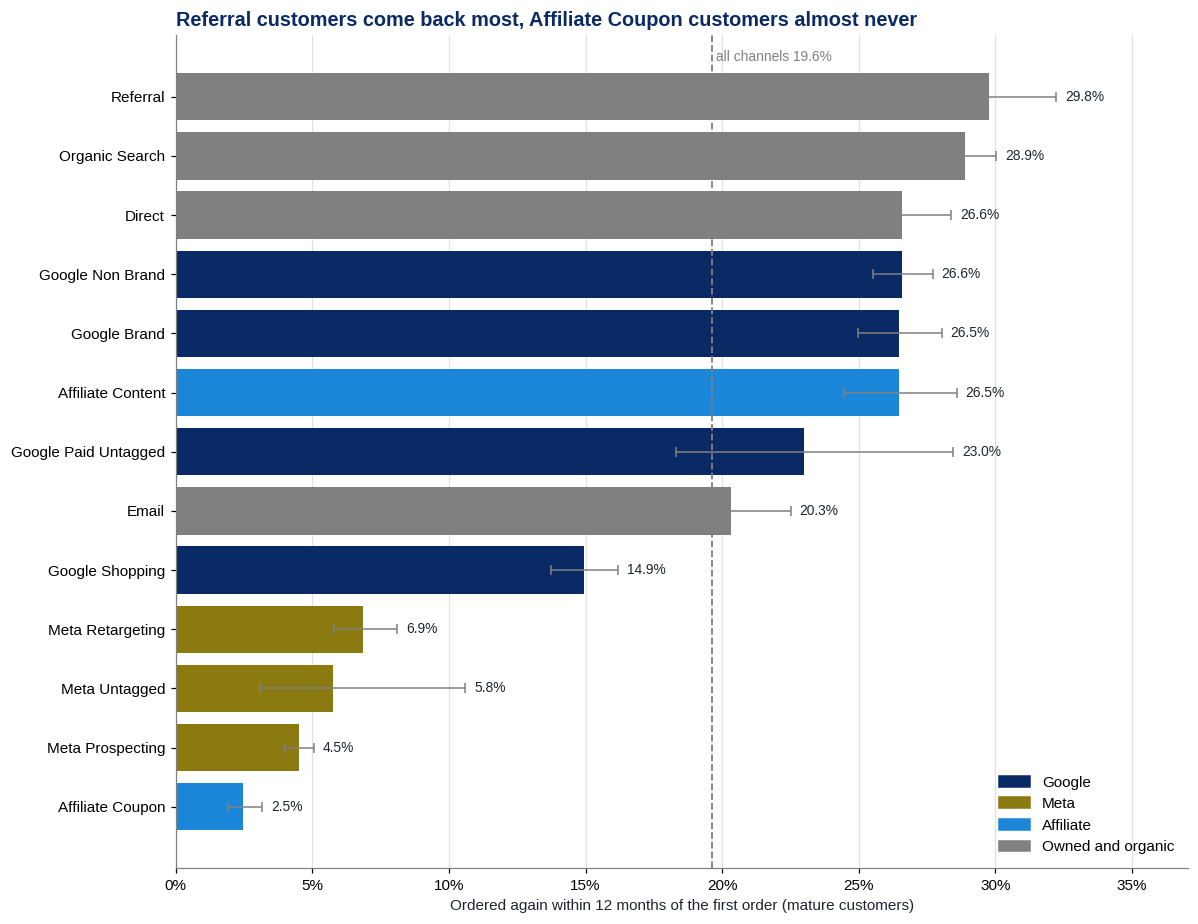

In [4]:
# 1. Repeaters over customers, per acquisition channel, mature customers only
rep = (mature.groupby('acquisition_channel')
             .agg(customers=('person_id', 'size'), repeaters=('repeated_within_12m', 'sum')))
rep['repeat_pct'] = 100 * rep['repeaters'] / rep['customers']
lo, hi = proportion_confint(rep['repeaters'], rep['customers'], alpha=0.05, method='wilson')
rep['ci_low_pct'], rep['ci_high_pct'] = 100 * lo, 100 * hi
rep = rep.sort_values('repeat_pct', ascending=False)
overall_repeat = 100 * rep['repeaters'].sum() / rep['customers'].sum()

# 2. Does repeat rate depend on channel, and which channels differ from the overall rate?
table = np.column_stack([rep['repeaters'], rep['customers'] - rep['repeaters']])
chi2, p_chi, dof, _ = stats.chi2_contingency(table)
rep['against_overall'] = np.select(
    [rep['ci_low_pct'] > overall_repeat, rep['ci_high_pct'] < overall_repeat],
    ['above, beyond noise', 'below, beyond noise'], default='not different from overall')

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('overall repeat rate',      overall_repeat,                            19.6, '{:.1f}%', 1)
check('Referral repeat rate',     rep.loc['referral', 'repeat_pct'],         29.8, '{:.1f}%', 1)
check('Affiliate Coupon repeat',  rep.loc['affiliate_coupon', 'repeat_pct'], 2.5,  '{:.1f}%', 1)
print(f'\nChi-square {chi2:,.1f} on {dof} degrees of freedom, p = {fmt_p(p_chi)}')
print(rep['against_overall'].value_counts().to_string())
out = rep.copy()
out.index = out.index.map(LABEL)
show(out, ints=['customers', 'repeaters'], pct=['repeat_pct', 'ci_low_pct', 'ci_high_pct'])

# 3. Ranked, with the intervals as whiskers
r = out['repeat_pct']
err = pd.DataFrame({'lo': out['repeat_pct'] - out['ci_low_pct'], 'hi': out['ci_high_pct'] - out['repeat_pct']})
hbar(r, lambda v: f'{v:.1f}%',
     title=f'{r.idxmax()} customers come back most, {r.idxmin()} customers almost never',
     xlabel='Ordered again within 12 months of the first order (mature customers)',
     err=err, ref=overall_repeat, ref_label=f'all channels {overall_repeat:.1f}%', axis_fmt='{x:.0f}%')

**Insight and business takeaway:**

Repeat rate depends on how a customer was acquired, by far more than chance could produce: chi-square 2,406.2 on 12 degrees of freedom. Referral leads at 29.8 percent and Affiliate Coupon trails at 2.5 percent, against 19.6 percent overall. Roughly three in ten referral customers order again within a year, and one in forty coupon customers.

Six channels sit above the average beyond noise: Referral, Organic Search, Direct, Google Non Brand, Google Brand and Affiliate Content. Five sit below it: Google Shopping, the three Meta channels and Affiliate Coupon. Email's interval runs from 18.3 to 22.5 percent around its 20.3, and Google Paid Untagged has only 261 customers, so neither can be told apart from the average.

The coupon result fits what a coupon site is. People go to a coupon site for a discount, so a low repeat rate is no surprise.

**Indication:** the split between channels whose customers return and channels whose customers buy once is real enough to plan on. A coupon customer is close to a one order customer, so whatever is paid to win one has to come back on that first order.

**Step 3.2: Twelve month gross profit per customer, and where it comes from**

This is twelve month LTV as defined in the data dictionary: gross profit from a customer in the 365 days after their first order, on mature customers. Gross profit is already after the books, delivery, payment fees, refunds and affiliate commission, so it is money the business keeps before marketing.

Each channel's figure is split into the first order and everything after it. If channels win on order size, the first order part differs most; if they win on people coming back, the later part does. `05_customer_value.sql` gave Referral highest at \\$140.44 and Affiliate Coupon lowest at \\$81.95.

                                                   this notebook        from SQL
Referral 12m gross profit                                $140.44         $140.44   matches
Affiliate Coupon 12m gross profit                         $81.95          $81.95   matches

All mature customers: $118.82 of gross profit per customer over 12 months
Spread, best to worst channel, gp_12m: $58.49
Spread, best to worst channel, first_order_gp: $25.04
Spread, best to worst channel, after_first_gp: $36.72


,customers,orders_12m,gp_12m,first_order_gp,after_first_gp
acquisition_channel,,,,,
Referral,"1,407",1.36,$140.44,$100.96,$39.48
Organic Search,"6,418",1.34,$134.75,$97.90,$36.85
Google Non Brand,"6,204",1.30,$134.66,$102.22,$32.44
Google Brand,"3,187",1.30,$131.65,$99.72,$31.93
Google Paid Untagged,261,1.26,$131.12,$104.24,$26.88
Direct,"2,470",1.31,$129.32,$96.79,$32.53
Affiliate Content,"1,749",1.29,$121.39,$86.88,$34.52
Email,"1,388",1.23,$118.95,$94.03,$24.92
Google Shopping,"3,289",1.16,$112.19,$95.24,$16.95


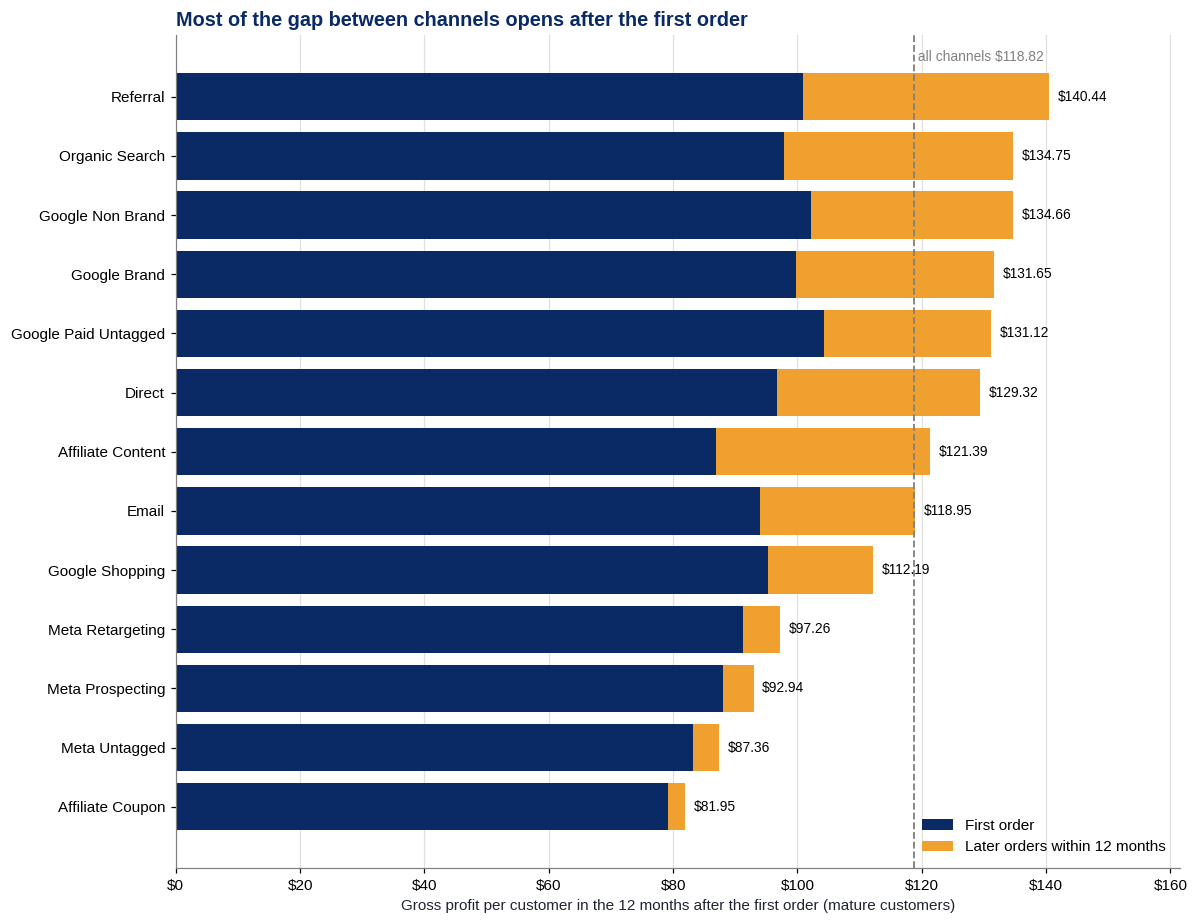

In [5]:
# 1. Average twelve month value per mature customer, and its parts
val = (mature.groupby('acquisition_channel')
             .agg(customers      =('person_id', 'size'),
                  orders_12m     =('orders_12m', 'mean'),
                  gp_12m         =('gross_profit_12m_usd', 'mean'),
                  first_order_gp =('first_order_gross_profit_usd', 'mean')))
val['after_first_gp'] = val['gp_12m'] - val['first_order_gp']
val = val.sort_values('gp_12m', ascending=False)
overall_gp12 = mature['gross_profit_12m_usd'].sum() / len(mature)

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('Referral 12m gross profit',         val.loc['referral', 'gp_12m'],         140.44, '${:,.2f}', 2)
check('Affiliate Coupon 12m gross profit', val.loc['affiliate_coupon', 'gp_12m'], 81.95,  '${:,.2f}', 2)
print(f"\nAll mature customers: ${overall_gp12:,.2f} of gross profit per customer over 12 months")
for part in ['gp_12m', 'first_order_gp', 'after_first_gp']:
    print(f"Spread, best to worst channel, {part}: ${val[part].max() - val[part].min():,.2f}")
out = val.copy()
out.index = out.index.map(LABEL)
show(out, ints=['customers'], dec=['orders_12m'], money=['gp_12m', 'first_order_gp', 'after_first_gp'])

# 2. First order in navy, later orders in amber, most valuable channel at the top
v = val.sort_values('gp_12m')
names = v.index.map(LABEL)
fig, ax = plt.subplots(figsize=(11, 0.5 * len(v) + 2))
ax.barh(names, v['first_order_gp'], color=NAVY, label='First order')
ax.barh(names, v['after_first_gp'], left=v['first_order_gp'], color=AMBER, label='Later orders within 12 months')
for i, total in enumerate(v['gp_12m']):
    ax.text(total + v['gp_12m'].max() * 0.01, i, f'${total:,.2f}', va='center', fontsize=9)
ax.axvline(overall_gp12, color=GREY, linestyle='--', linewidth=1.2)
ax.text(overall_gp12, len(v) - 0.45, f' all channels ${overall_gp12:,.2f}', color=GREY, fontsize=9, va='bottom')
ax.set_xlim(0, v['gp_12m'].max() * 1.15)
ax.set_xlabel('Gross profit per customer in the 12 months after the first order (mature customers)')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.grid(axis='x', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Most of the gap between channels opens after the first order', loc='left')
plt.tight_layout()
plt.show()

**Insight and business takeaway:**

Referral customers bring \$140.44 of gross profit in their first year and Affiliate Coupon customers \$81.95, a gap of \$58.49. Most of it opens after the first order. Referral's first order earns \$100.96 against coupon's \$79.19, so \$21.77 of the gap is a smaller first basket; later orders add \$39.48 against \$2.76, which is the other \$36.72. Across all thirteen channels, first orders differ by \$25.04 at most and later orders by \$36.72.

Meta Prospecting shows the pattern clearly. Its first order earns \$87.99, not far below Email's \$94.03, yet its later orders add \$4.95 against Email's \$24.92.

**Indication:** judging channels on the first order, which is what ROAS does, misses most of the difference between them. That is why the unit economics table carries twelve month gross profit forward.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 4: Acquisition Cost, Payback and Break Even</h2>

**Step 4.1: What a customer cost, and LTV to CAC**

Three kinds of channel, three answers:

- **Paid channels with spend** (the five tagged Google and Meta channels): ad spend over the new customers the channel brought in. All of a channel's spend is charged to new customers, even though Google Brand and Meta Retargeting also win orders from existing ones, which errs on the cautious side.
- **Affiliates** are paid per sale, so a customer costs the commission on their first order.
- **Everything else** (Email, Organic Search, Direct, Referral and the two untagged paid buckets) has no cost recorded against it, so its CAC is left blank rather than shown as zero.

The full three years reconciles with the cost per new customer in the Power BI report. The ratio uses the mature window instead, spend and new customers up to 30 September 2024, so cost and value describe the same people. Gross profit already has affiliate commission taken out, so for the two affiliate channels the first order commission is added back to the value side before dividing, or the cost would count twice. The whole business row uses ad spend over every new customer, not blended CAC, for the same reason.

                                                   this notebook        from SQL
Meta Prospecting CAC, full window                         $52.54          $52.54   matches
Google Non Brand CAC, full window                         $34.89          $34.89   matches
Google Shopping CAC, full window                          $35.87          $35.87   matches
Meta Retargeting CAC, full window                         $39.85          $39.85   matches
Google Brand CAC, full window                             $15.59          $15.59   matches
ad spend per new customer, all channels                   $21.47          $21.47   matches
mature new customers, cost vs people                           0               0   matches

All channels: ad spend per new customer $20.46 in the mature window, 12m gross profit $118.82, LTV to CAC 5.81


,cost_basis,customers,cac_full,cac_mature,ltv_before_acq,ltv_to_cac
acquisition_channel,,,,,,
Google Brand,Ad spend,"3,187",$15.59,$14.49,$131.65,9.09
Affiliate Coupon,Commission on first order,"2,438",$11.00,$11.03,$92.99,8.43
Affiliate Content,Commission on first order,"1,749",$16.70,$16.56,$137.96,8.33
Google Non Brand,Ad spend,"6,204",$34.89,$33.02,$134.66,4.08
Google Shopping,Ad spend,"3,289",$35.87,$36.41,$112.19,3.08
Meta Retargeting,Ad spend,"1,823",$39.85,$38.84,$97.26,2.50
Meta Prospecting,Ad spend,"5,779",$52.54,$53.08,$92.94,1.75
Referral,No cost data,"1,407",,,$140.44,
Organic Search,No cost data,"6,418",,,$134.75,


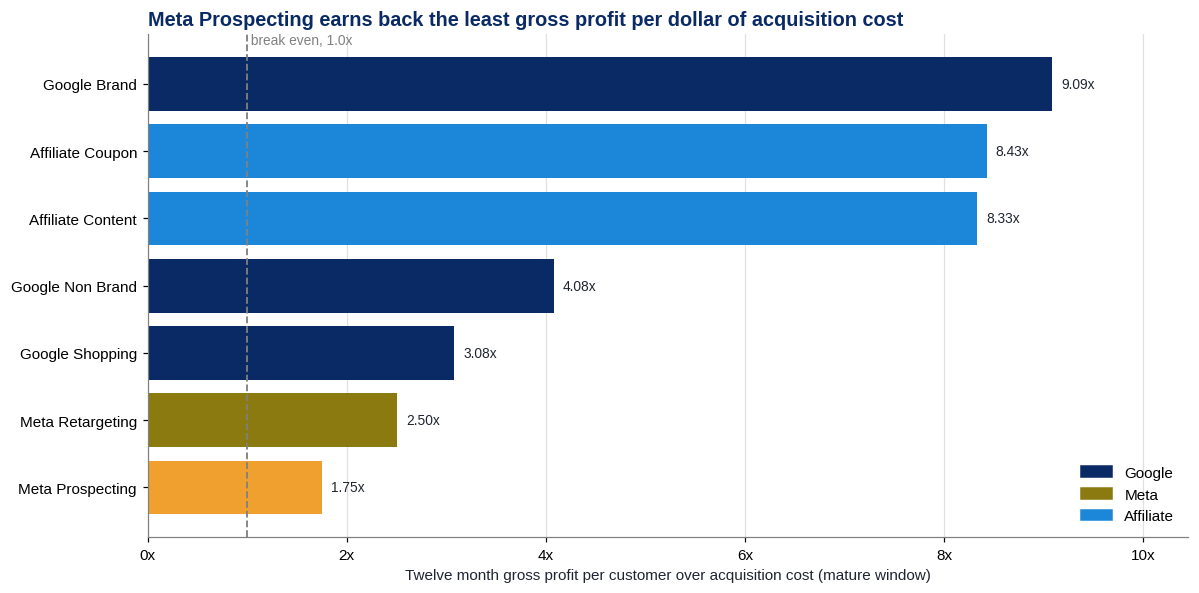

In [6]:
# 1. The two windows side by side
full = cost.groupby('channel')[['spend_usd', 'new_customers']].sum()
win  = cost[cost['in_mature_window']].groupby('channel')[['spend_usd', 'new_customers']].sum()
ue = val[['customers', 'gp_12m', 'first_order_gp']].copy()
has_spend = full['spend_usd'].reindex(ue.index) > 0
ue['cost_basis'] = np.where(has_spend, 'Ad spend', 'No cost data')
ue['cac_full']   = (full['spend_usd'] / full['new_customers']).reindex(ue.index).where(has_spend)
ue['cac_mature'] = (win['spend_usd'] / win['new_customers']).reindex(ue.index).where(has_spend)

# 2. Affiliates: the commission on the first order is the price of the customer
ue['first_order_commission'] = mature.groupby('acquisition_channel')['first_order_commission_usd'].mean()
for a in ['affiliate_coupon', 'affiliate_content']:
    ue.loc[a, 'cac_full']   = cv.loc[cv.acquisition_channel == a, 'first_order_commission_usd'].mean()
    ue.loc[a, 'cac_mature'] = ue.loc[a, 'first_order_commission']
    ue.loc[a, 'cost_basis'] = 'Commission on first order'

# 3. Value before acquisition cost (commission added back for affiliates), and the ratio
is_aff = ue['cost_basis'] == 'Commission on first order'
ue['ltv_before_acq'] = ue['gp_12m'] + np.where(is_aff, ue['first_order_commission'], 0)
ue['ltv_to_cac']     = ue['ltv_before_acq'] / ue['cac_mature']
all_cac_full   = full['spend_usd'].sum() / full['new_customers'].sum()
all_cac_mature = win['spend_usd'].sum() / win['new_customers'].sum()
all_ltv_to_cac = overall_gp12 / all_cac_mature

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
report_cac = {'meta_prospecting': 52.54, 'google_nonbrand': 34.89, 'google_shopping': 35.87,
              'meta_retargeting': 39.85, 'google_brand': 15.59}
for chan, v in report_cac.items():
    check(f'{LABEL[chan]} CAC, full window', ue.loc[chan, 'cac_full'], v, '${:,.2f}', 2)
check('ad spend per new customer, all channels', all_cac_full, 21.47, '${:,.2f}', 2)
check('mature new customers, cost vs people', (win['new_customers'] - mature.groupby('acquisition_channel').size()).abs().sum(), 0)
print(f'\nAll channels: ad spend per new customer ${all_cac_mature:,.2f} in the mature window, '
      f'12m gross profit ${overall_gp12:,.2f}, LTV to CAC {all_ltv_to_cac:.2f}')
out = ue[['cost_basis', 'customers', 'cac_full', 'cac_mature', 'ltv_before_acq', 'ltv_to_cac']].copy()
out.index = out.index.map(LABEL)
show(out.sort_values('ltv_to_cac', ascending=False),
     ints=['customers'], money=['cac_full', 'cac_mature', 'ltv_before_acq'], dec=['ltv_to_cac'])

# 4. Only channels with a cost can have a ratio; the weakest in amber
costed = out['ltv_to_cac'].dropna()
weakest = costed.idxmin()
colours = {k: (AMBER if k == weakest else COLOUR_BY_LABEL[k]) for k in costed.index}
hbar(costed, lambda v: f'{v:.2f}x',
     title=f'{weakest} earns back the least gross profit per dollar of acquisition cost',
     xlabel='Twelve month gross profit per customer over acquisition cost (mature window)',
     colours=colours, ref=1, ref_label='break even, 1.0x', axis_fmt='{x:.0f}x', legend=True)

**Insight and business takeaway:**

Every channel with a cost earns back more than it cost within a year. Google Brand returns 9.09 times its acquisition cost, Affiliate Coupon 8.43, Affiliate Content 8.33, Google Non Brand 4.08 and Google Shopping 3.08. Meta Retargeting at 2.50 and Meta Prospecting at 1.75 are the two below the common rule of thumb of 3. Across the business, \$118.82 of twelve month gross profit against \$20.46 of ad spend per new customer comes to 5.81 times.

Cost per new customer barely moves between the two windows: Meta Prospecting is \$53.08 on customers acquired up to September 2024 against \$52.54 over three years, Google Brand \$14.49 against \$15.59. So the mature window changes no ranking. Affiliate Coupon is the cheapest customer, at \$11.03 of first order commission, and Meta Prospecting costs more than three times what Google Brand does.

**Indication:** the order needs a warning beside it. Two of the three channels at the top, Google Brand and Affiliate Coupon, are the ones most likely to be credited with people already on their way: someone typing the shop's name into Google, or looking for a code while buying. Affiliate Content is different: content partners mostly start journeys rather than finish them, as the attribution notebook shows. This ranking shows the most each channel could be worth. On its own it is not a reason to move money from Meta into brand search or coupon sites.

**Step 4.2: Payback, and how much room each channel has**

Payback is the number of months until a cohort's running gross profit per customer passes its acquisition cost, read from the grid in Section 2 on mature cohorts only, so every cohort has lived all twelve months. Month 0 is the month of the first order, and months are calendar months, so month 12 holds a little more than 365 days of orders.

Two more measures say how much worse things could get before a channel stops paying:

- **Break even incrementality**: CAC over twelve month value before acquisition cost. Last click assumes every customer credited to a channel would not have come otherwise. If only a share of them are genuinely new, the cost per genuinely new customer is higher, and the channel breaks even over the year only if that share is at least this figure. Lower is safer. This data holds no holdout or experiment, so the actual share cannot be measured here; the budget planner tests a range of shares against this line.
- **Break even CAC**: the CAC at which twelve months of gross profit only just covers acquisition cost, which is the twelve month value itself, and the headroom between it and today's CAC.

                                                   this notebook        from SQL
mature customers in month 0 of the grid                   36,569          36,569   matches
same customers in month 12                                36,569          36,569   matches
costed channels paying back in month 0                         7               7   matches


,cac_mature,month 0,month 3,month 6,month 12,payback,breakeven_cac,cac_headroom_pct,breakeven_incrementality_pct
acquisition_channel,,,,,,,,,
Meta Prospecting,$53.08,$88.01,$88.69,$89.85,$93.21,month 0,$92.94,75.1%,57.1%
Meta Retargeting,$38.84,$91.29,$91.90,$93.34,$98.03,month 0,$97.26,150.4%,39.9%
Google Shopping,$36.41,$95.29,$97.63,$102.47,$112.78,month 0,$112.19,208.1%,32.5%
Google Non Brand,$33.02,$102.44,$107.51,$116.78,$136.01,month 0,$134.66,307.8%,24.5%
Affiliate Content,$16.56,$103.61,$109.27,$119.16,$139.62,month 0,$137.96,733.0%,12.0%
Affiliate Coupon,$11.03,$90.23,$90.44,$91.27,$93.06,month 0,$92.99,742.7%,11.9%
Google Brand,$14.49,$99.76,$104.54,$113.77,$133.65,month 0,$131.65,808.6%,11.0%


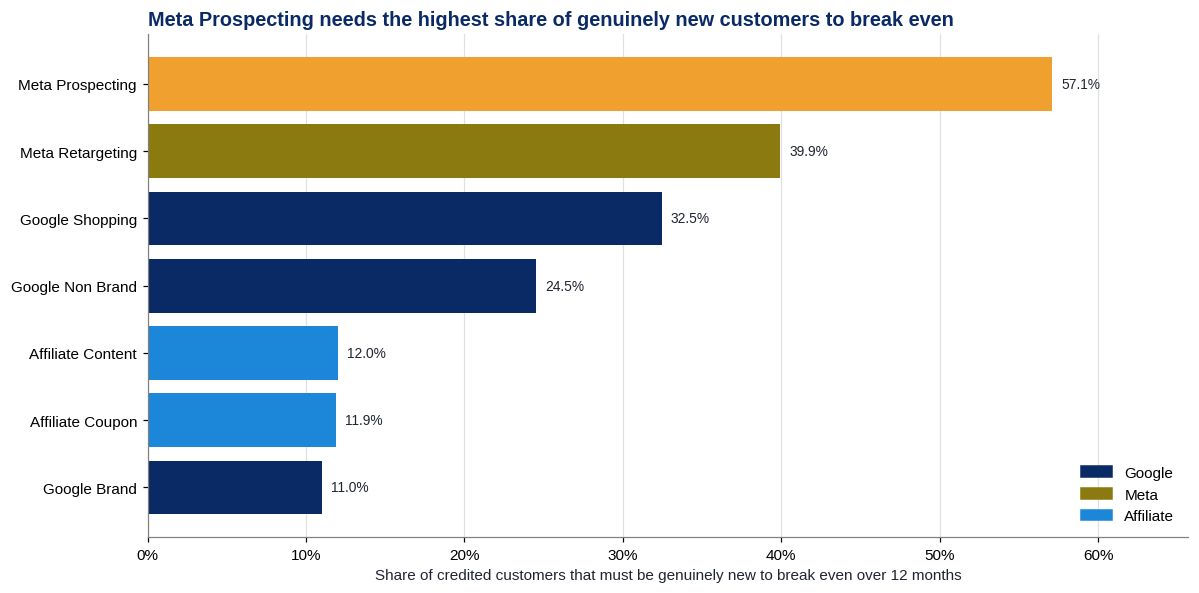

In [7]:
# 1. Running gross profit per customer on mature cohorts, affiliates with first order commission added back
mg = grid[grid['cohort_month'] <= '2024-09-01']
pay = (mg.groupby(['acquisition_channel', 'month_index'])
         .agg(gp=('gross_profit_usd', 'sum'), customers=('cohort_size', 'sum')).reset_index())
pay['cum_gp_per_customer'] = pay.groupby('acquisition_channel')['gp'].cumsum() / pay['customers']
pay['cum_gp_per_customer'] += np.where(pay['acquisition_channel'].map(is_aff),
                                       pay['acquisition_channel'].map(ue['first_order_commission']), 0)

# 2. The first month in which the running total passes CAC
pay['cac'] = pay['acquisition_channel'].map(ue['cac_mature'])
payback = pay[pay['cum_gp_per_customer'] >= pay['cac']].groupby('acquisition_channel')['month_index'].min()
cum = pay.pivot(index='acquisition_channel', columns='month_index', values='cum_gp_per_customer')
pb = pd.DataFrame({'cac_mature': ue['cac_mature'], 'month 0': cum[0], 'month 3': cum[3],
                   'month 6': cum[6], 'month 12': cum[12]})
pb['payback_month'] = payback.reindex(pb.index).astype('Int64')
pb['payback'] = np.where(pb['cac_mature'].isna(), 'no cost data',
                np.where(pb['payback_month'].isna(), 'beyond month 12',
                         'month ' + pb['payback_month'].astype(str)))

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('mature customers in month 0 of the grid', pay.loc[pay.month_index == 0, 'customers'].sum(), 36569)
check('same customers in month 12',              pay.loc[pay.month_index == 12, 'customers'].sum(), 36569)
check('costed channels paying back in month 0',  (pb['payback_month'] == 0).sum(), 7)

# 3. Room: break even CAC, headroom and break even incrementality
ue['breakeven_cac']                = ue['ltv_before_acq'].where(ue['cac_mature'].notna())
ue['cac_headroom_pct']             = 100 * (ue['breakeven_cac'] / ue['cac_mature'] - 1)
ue['breakeven_incrementality_pct'] = 100 * ue['cac_mature'] / ue['ltv_before_acq']
room = pb.join(ue[['breakeven_cac', 'cac_headroom_pct', 'breakeven_incrementality_pct']]).dropna(subset=['cac_mature'])
room.index = room.index.map(LABEL)
show(room.drop(columns='payback_month').sort_values('breakeven_incrementality_pct', ascending=False),
     money=['cac_mature', 'month 0', 'month 3', 'month 6', 'month 12', 'breakeven_cac'],
     pct=['cac_headroom_pct', 'breakeven_incrementality_pct'])

# 4. The channel with least room in amber
s = room['breakeven_incrementality_pct']
tight = s.idxmax()
colours = {k: (AMBER if k == tight else COLOUR_BY_LABEL[k]) for k in s.index}
hbar(s, lambda v: f'{v:.1f}%',
     title=f'{tight} needs the highest share of genuinely new customers to break even',
     xlabel='Share of credited customers that must be genuinely new to break even over 12 months',
     colours=colours, axis_fmt='{x:.0f}%', legend=True)

**Insight and business takeaway:**

All seven channels with a cost pay back in month 0. Even Meta Prospecting, the dearest at \$53.08, collects \$88.01 of gross profit per customer in the month of the first order. After that the channels part. Meta Prospecting's running total creeps to \$93.21 by month 12 and Affiliate Coupon's from \$90.23 to \$93.06, while Google Non Brand climbs from \$102.44 to \$136.01 and Affiliate Content from \$103.61 to \$139.62.

Since payback cannot separate them, room does. Meta Prospecting's break even CAC is \$92.94 against \$53.08 today, 75.1 percent of headroom. Put the other way, at least 57.1 percent of the customers last click gives it must be genuinely new for it to break even over a year. Meta Retargeting needs 39.9 percent and Google Shopping 32.5 percent. Google Brand and both affiliate types need only 11.0 to 12.0 percent.

**Indication:** on last click, none of this spend waits long for a return. The open question is incrementality, and it matters most for the channels at the top of the chart. A holdout test on Meta Prospecting is the way to find out which side of its 57.1 percent line it sits.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 5: Customers First Acquired in a Sale</h2>

**Step 5.1: Sale code customers against everyone else**

`05_customer_value.sql` puts every person in one of three groups by their first order: **sale, used the code**; **sale period, full price** (a sale day, no code); and **outside any sale**. The middle group matters: comparing only code against no code would mix full price sale day buyers into the full price side, and sale days have their own kind of customer.

The worry being tested is a common one: a sale buys customers who only wanted the discount and never come back. If so, the code group should show a lower repeat rate and lower twelve month gross profit than the outside group. Repeat rate is tested with a two proportion z-test and value with Welch's t-test. Then the gap is worked out again within the same calendar month of the first order and within the same acquisition channel, weighted by code customers, because back to college runs at term start and some channels send more sale buyers than others. A Cochran-Mantel-Haenszel test says whether the repeat gap left within channel is more than noise.

mature customers across the three groups                  36,569          36,569   matches


,customers,first_order_aov,first_order_disc,first_order_gp,gp_12m,share_pct,repeat_pct,after_first_gp
first_order_price_group,,,,,,,,
"sale, used the code","9,447",$124.32,$32.12,$71.06,$92.54,25.8%,18.0%,$21.48
"sale period, full price","4,126",$167.37,$0.00,$106.06,$138.97,11.3%,24.9%,$32.92
outside any sale,"22,996",$159.59,$0.00,$102.47,$126.01,62.9%,19.3%,$23.54


sale, used the code against outside any sale
  repeat rate gap       -1.4 points   p = 0.00457   real
  12m gross profit gap  -$33.47   p = 1.81e-195   real

sale period, full price against outside any sale
  repeat rate gap       +5.6 points   p = 2.19e-16   real
  12m gross profit gap  +$12.96   p = 1.73e-11   real



,"repeat rate gap, points",12m gross profit gap
raw gap,-1.36,-$33.47
within the same month,-1.40,-$33.86
within the same channel,-0.64,-$32.11



Repeat gap within channel: 13 channels, Cochran-Mantel-Haenszel p = 0.175, noise


,customers,discount,repeat_pct,gp_12m
first_order_sale_name,,,,
back_to_college,"5,250",$31.76,17.9%,$93.12
black_friday,"1,437",$49.00,18.4%,$76.61
mid_year,"1,422",$24.17,18.3%,$101.22
new_year,"1,338",$23.86,17.5%,$98.16



Where code customers were acquired, top five channels (percent of code customers):
acquisition_channel
Meta Prospecting    17.7
Organic Search      17.2
Google Non Brand    15.8
Google Shopping      9.3
Google Brand         7.9


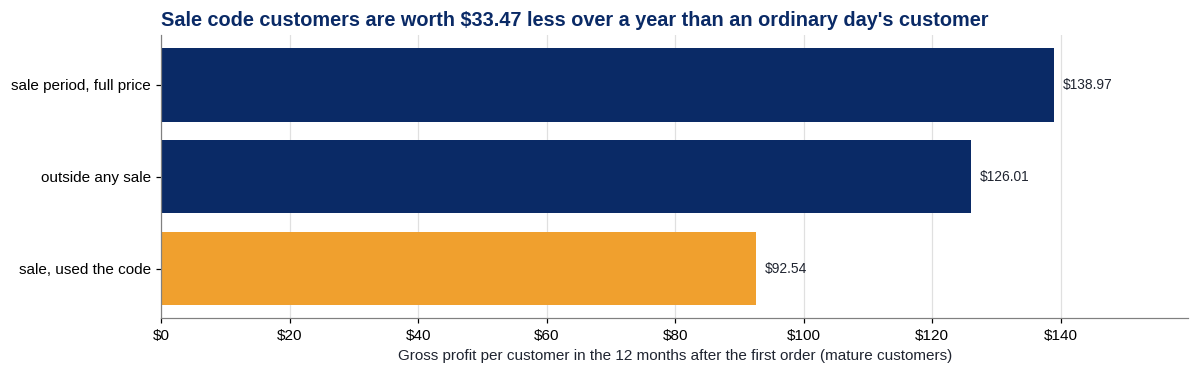

In [8]:
# 1. One row per group, mature customers only
order = ['sale, used the code', 'sale period, full price', 'outside any sale']
grp = (mature.groupby('first_order_price_group')
             .agg(customers        =('person_id', 'size'),
                  first_order_aov  =('first_order_net_revenue_usd', 'mean'),
                  first_order_disc =('first_order_discount_usd', 'mean'),
                  first_order_gp   =('first_order_gross_profit_usd', 'mean'),
                  repeaters        =('repeated_within_12m', 'sum'),
                  gp_12m           =('gross_profit_12m_usd', 'mean'))).reindex(order)
grp['share_pct']      = 100 * grp['customers'] / grp['customers'].sum()
grp['repeat_pct']     = 100 * grp['repeaters'] / grp['customers']
grp['after_first_gp'] = grp['gp_12m'] - grp['first_order_gp']
check('mature customers across the three groups', grp['customers'].sum(), 36569)
show(grp.drop(columns='repeaters'), ints=['customers'], pct=['share_pct', 'repeat_pct'],
     money=['first_order_aov', 'first_order_disc', 'first_order_gp', 'gp_12m', 'after_first_gp'])

# 2. Each group against outside any sale
mature['first_month'] = mature['first_order_date'].dt.month
base = mature[mature.first_order_price_group == 'outside any sale']
tests = {}
for g in order[:2]:
    a = mature[mature.first_order_price_group == g]
    _, p_rep = proportions_ztest([a.repeated_within_12m.sum(), base.repeated_within_12m.sum()], [len(a), len(base)])
    _, p_gp  = stats.ttest_ind(a.gross_profit_12m_usd, base.gross_profit_12m_usd, equal_var=False)
    tests[g] = (100 * (a.repeated_within_12m.mean() - base.repeated_within_12m.mean()), p_rep,
                a.gross_profit_12m_usd.mean() - base.gross_profit_12m_usd.mean(), p_gp)
    verdict = lambda p: 'real' if p < 0.05 else 'noise'
    print(f'{g} against outside any sale')
    print(f'  repeat rate gap       {tests[g][0]:+.1f} points   p = {p_rep:.3g}   {verdict(p_rep)}')
    print(f'  12m gross profit gap  {signed_usd(tests[g][2])}   p = {p_gp:.3g}   {verdict(p_gp)}\n')

# 3. The code gap within the same month and within the same channel, weighted by code customers
code_grp = mature[mature.first_order_price_group == 'sale, used the code']
def adjusted_gap(by, metric, scale=1):
    a = code_grp.groupby(by)[metric].agg(['mean', 'size'])
    j = a.join(base.groupby(by)[metric].mean().rename('base'), how='inner')
    return scale * np.average(j['mean'] - j['base'], weights=j['size'])
adj = pd.DataFrame({
    'repeat rate gap, points': [tests[order[0]][0], adjusted_gap('first_month', 'repeated_within_12m', 100),
                                adjusted_gap('acquisition_channel', 'repeated_within_12m', 100)],
    '12m gross profit gap': [tests[order[0]][2], adjusted_gap('first_month', 'gross_profit_12m_usd'),
                             adjusted_gap('acquisition_channel', 'gross_profit_12m_usd')]},
    index=['raw gap', 'within the same month', 'within the same channel'])
display(pd.DataFrame({'repeat rate gap, points': adj['repeat rate gap, points'].map(lambda v: f'{v:+.2f}'),
                      '12m gross profit gap': adj['12m gross profit gap'].map(signed_usd)}))
strata = []
for chan in sorted(code_grp['acquisition_channel'].unique()):
    a = code_grp.loc[code_grp.acquisition_channel == chan, 'repeated_within_12m']
    b = base.loc[base.acquisition_channel == chan, 'repeated_within_12m']
    if len(a) and len(b):
        strata.append(np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]))
cmh_p = StratifiedTable(strata).test_null_odds(correction=True).pvalue
print(f"\nRepeat gap within channel: {len(strata)} channels, Cochran-Mantel-Haenszel p = {cmh_p:.3g}, "
      f"{'real' if cmh_p < 0.05 else 'noise'}")

# 4. Code customers by sale
mix = (code_grp.groupby('first_order_sale_name')
               .agg(customers=('person_id', 'size'), discount=('first_order_discount_usd', 'mean'),
                    repeaters=('repeated_within_12m', 'sum'), gp_12m=('gross_profit_12m_usd', 'mean')))
mix['repeat_pct'] = 100 * mix['repeaters'] / mix['customers']
show(mix.sort_values('customers', ascending=False)[['customers', 'discount', 'repeat_pct', 'gp_12m']],
     ints=['customers'], money=['discount', 'gp_12m'], pct=['repeat_pct'])

top_channels = (code_grp['acquisition_channel'].value_counts(normalize=True) * 100).head(5)
top_channels.index = top_channels.index.map(LABEL)
print('\nWhere code customers were acquired, top five channels (percent of code customers):')
print(top_channels.round(1).to_string())

# 5. Twelve month value by group, the code group in amber
colours = {g: (AMBER if g == order[0] else NAVY) for g in order}
hbar(grp['gp_12m'], lambda v: f'${v:,.2f}',
     title=f"Sale code customers are worth ${-tests[order[0]][2]:,.2f} less over a year than "
           f"an ordinary day's customer",
     xlabel='Gross profit per customer in the 12 months after the first order (mature customers)',
     colours=colours, axis_fmt='${x:,.0f}', legend=False)

**Insight and business takeaway:**

Customers whose first order used a sale code are worth \$92.54 of gross profit over twelve months, against \$126.01 for customers who first bought on an ordinary day. The \$33.47 gap is far beyond noise (p = 1.81e-195), and the group is 25.8 percent of mature customers.

Most of the gap is the first order. The code group's first basket is \$124.32 after refunds against \$159.59, and carries \$32.12 of discount, so it earns \$71.06 of gross profit against \$102.47. After that the two groups behave much alike: \$21.48 against \$23.54 of further gross profit, and a repeat rate of 18.0 against 19.3 percent.

That 1.4 point repeat gap is real on its face (p = 0.00457), but it shrinks once channel is allowed for. It barely moves within the same calendar month (1.40 points) and halves within the same acquisition channel (0.64 points), where it is noise (Cochran-Mantel-Haenszel p = 0.175). Code customers come most often through Meta Prospecting, 17.7 percent of them, whose customers rarely return. The value gap hardly moves under either adjustment (\$33.86 and \$32.11), because it is the discount.

People who bought on a sale day without the code are the most valuable group: \$138.97 over twelve months and a 24.9 percent repeat rate, \$12.96 and 5.6 points above ordinary day customers, both real. Black Friday stands apart among the sales. Its code customers took the deepest first order discount, \$49.00, and are worth the least, \$76.61; Mid Year and New Year customers took about \$24 and are worth \$101.22 and \$98.16.

**Indication:** the code group's lower value is almost all the discount on its first order, so the depth of the discount sets the cost, and Black Friday's is the first to question.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 6: Lifecycle Stages for CRM</h2>

**Step 6.1: RFM groups and lifecycle stages**

`05_customer_value.sql` scores every person on recency (days since the last order, to 30 September 2025), frequency (fixed bands of 1, 2, 3, 4 or 5, and 6 or more orders, because 77.6 percent of people have one order) and monetary value (lifetime gross profit), each from 1 to 5. Recency and monetary are cut into fifths with tied values kept in the same score. Ten RFM groups come from recency and frequency, and they roll up into four lifecycle stages: New, Active repeat, Cooling and Lapsed.

The scores are read here, not worked out again. The first check confirms that no value of any measure was split across two scores. The table shows what each group and stage is worth over its lifetime and how many people CRM is allowed to email.

                                                   this notebook        from SQL
most R, F and M scores for one value                           1               1   matches
people across the four stages                             58,101          58,101   matches
people CRM can email                                      37,183          37,183   matches
Lapsed people                                             23,234          23,234   matches


people avg_orders gp_per_person opted_in  \
lifecycle_stage rfm_group                                                       
New             Promising             7,910       1.00        $99.65    5,099   
                New customers         7,941       1.00        $88.95    5,063   
Active repeat   Champions               772       4.33       $490.96      509   
                Loyal                 2,355       3.08       $338.23    1,540   
                Potential loyalists   4,898       2.00       $208.12    3,071   
Cooling         Needs attention       2,078       2.00       $199.16    1,344   
                About to sleep        8,913       1.00        $89.07    5,656   
Lapsed          At risk                 389       3.13       $344.89      246   
                Hibernating           2,543       2.00       $209.83    1,603   
                Lost                 20,302       1.00        $91.42   13,052   

                                    share_of_people_pct share_of_gp_pct  \
lifecycle_stage rfm_group                                                 
New             Promising                         13.6%           10.6%   
                New customers                     13.7%            9.5%   
Active repeat   Champions                          1.3%            5.1%   
                Loyal                              4.1%           10.7%   
                Potential loyalists                8.4%           13.7%   
Cooling         Needs attention                    3.6%            5.6%   
                About to sleep                    15.3%           10.7%   
Lapsed          At risk                            0.7%            1.8%   
                Hibernating                        4.4%            7.2%   
                Lost                              34.9%           25.0%   

                                    opt_in_pct  
lifecycle_stage rfm_group                       
New             Promising                64.5%  
                New customers            63.8%  
Active repeat   Champions                65.9%  
                Loyal                    65.4%  
                Potential loyalists      62.7%  
Cooling         Needs attention          64.7%  
                About to sleep           63.5%  
Lapsed          At risk                  63.2%  
                Hibernating              63.0%  
                Lost                     64.3%

,people,avg_orders,gp_per_person,opted_in,share_of_people_pct,share_of_gp_pct,opt_in_pct
lifecycle_stage,,,,,,,
New,"15,851",1.00,$94.29,"10,162",27.3%,20.1%,64.1%
Active repeat,"8,025",2.54,$273.51,"5,120",13.8%,29.6%,63.8%
Cooling,"10,991",1.19,$109.89,"7,000",18.9%,16.3%,63.7%
Lapsed,"23,234",1.15,$108.63,"14,901",40.0%,34.0%,64.1%


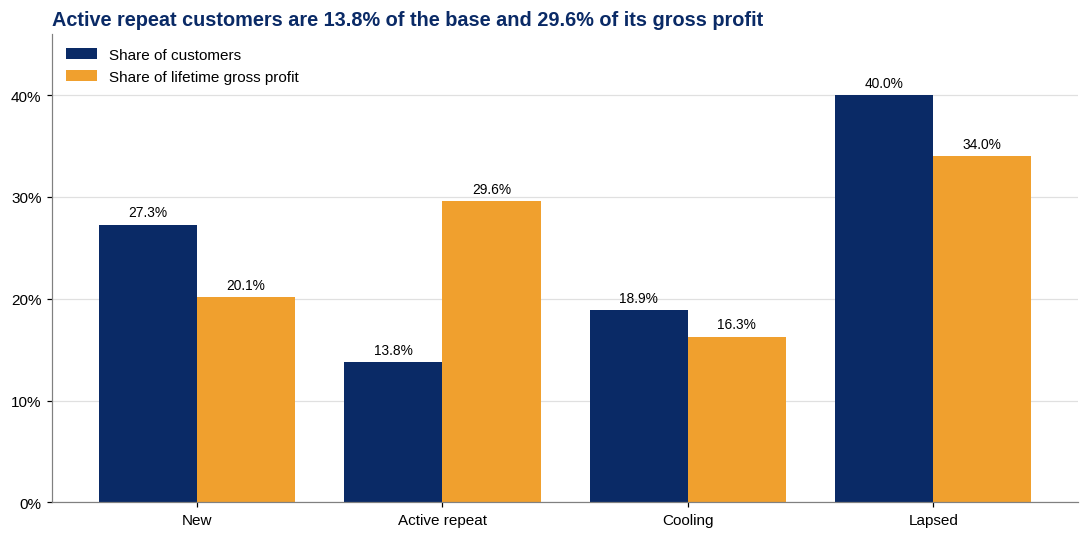

In [9]:
# 1. Ties kept together: the most scores any single value received
ties = [cv.groupby('recency_days')['r_score'].nunique().max(),
        cv.groupby('orders')['f_score'].nunique().max(),
        cv.groupby(cv['gross_profit_usd'].mul(100).round())['m_score'].nunique().max()]
print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('most R, F and M scores for one value', max(ties), 1)

# 2. The ten groups and four stages
STAGES = ['New', 'Active repeat', 'Cooling', 'Lapsed']
total_gp = cv['gross_profit_usd'].sum()
def profile(by):
    g = cv.groupby(by).agg(people=('person_id', 'size'), avg_orders=('orders', 'mean'),
                           gp_per_person=('gross_profit_usd', 'mean'), gp=('gross_profit_usd', 'sum'),
                           opted_in=('marketing_opt_in', 'sum'))
    g['share_of_people_pct'] = 100 * g['people'] / len(cv)
    g['share_of_gp_pct']     = 100 * g['gp'] / total_gp
    g['opt_in_pct']          = 100 * g['opted_in'] / g['people']
    return g.drop(columns='gp')
groups = profile(['lifecycle_stage', 'rfm_group']).reset_index()
groups['stage_order'] = groups['lifecycle_stage'].map(STAGES.index)
groups = (groups.sort_values(['stage_order', 'gp_per_person'], ascending=[True, False])
                .drop(columns='stage_order').set_index(['lifecycle_stage', 'rfm_group']))
stages = profile('lifecycle_stage').reindex(STAGES)
check('people across the four stages', stages['people'].sum(), 58101)
check('people CRM can email', stages['opted_in'].sum(), 37183)
check('Lapsed people', stages.loc['Lapsed', 'people'], 23234)
show(groups, ints=['people', 'opted_in'], dec=['avg_orders'], money=['gp_per_person'],
     pct=['share_of_people_pct', 'share_of_gp_pct', 'opt_in_pct'])
show(stages, ints=['people', 'opted_in'], dec=['avg_orders'], money=['gp_per_person'],
     pct=['share_of_people_pct', 'share_of_gp_pct', 'opt_in_pct'])

# 3. Share of people against share of gross profit, by stage
x = np.arange(len(STAGES))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.2, stages['share_of_people_pct'], width=0.4, color=NAVY, label='Share of customers')
ax.bar(x + 0.2, stages['share_of_gp_pct'], width=0.4, color=AMBER, label='Share of lifetime gross profit')
for i, (a, b) in enumerate(zip(stages['share_of_people_pct'], stages['share_of_gp_pct'])):
    ax.text(i - 0.2, a + 0.8, f'{a:.1f}%', ha='center', fontsize=9)
    ax.text(i + 0.2, b + 0.8, f'{b:.1f}%', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(STAGES)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, stages[['share_of_people_pct', 'share_of_gp_pct']].values.max() * 1.15)
ax.grid(axis='y', color='#E0E0E0')
ax.set_axisbelow(True)
ax.legend(frameon=False)
ar = stages.loc['Active repeat']
ax.set_title(f"Active repeat customers are {ar['share_of_people_pct']:.1f}% of the base "
             f"and {ar['share_of_gp_pct']:.1f}% of its gross profit", loc='left')
plt.tight_layout()
plt.show()

**Insight and business takeaway:**

No value of recency, frequency or monetary value was split across two scores, so the stages are safe to filter on.

Active repeat customers are 13.8 percent of the base and 29.6 percent of its lifetime gross profit, \$273.51 each. Champions and Loyal together are 5.4 percent of people and 15.8 percent of gross profit. Lapsed is the largest stage, 23,234 people or 40.0 percent, and still holds 34.0 percent of gross profit because there are so many of them. The 15,851 New customers have one order each, worth \$94.29 on average so far.

A second order roughly doubles what a customer is worth. Potential loyalists, recent and on two orders, average \$208.12 against \$88.95 and \$99.65 for the two recent one order groups. Opt in hardly moves between groups, 62.7 to 65.9 percent, so every stage can be reached in about the same proportion.

**Indication:** the main job for CRM is the second order. The New stage is where it starts, and Section 2 says when to ask: before the next term, not the month after the first order.

**Step 6.2: CRM audiences**

An audience here is a filter on `customer_value`, not a new table: people who have opted in to marketing email, by lifecycle stage and by how their first order was priced. The sale group says who first came in on a discount, which matters for what an email offers them. Lifetime gross profit per person sits beside each count, so the size of an audience can be read against what its people have been worth so far.

In [10]:
# 1. Emailable people by stage and first order price group
emailable = cv[cv['marketing_opt_in']]
aud = emailable.pivot_table(index='lifecycle_stage', columns='first_order_price_group', values='person_id',
                            aggfunc='count', fill_value=0).reindex(index=STAGES, columns=order)
aud['all emailable'] = aud.sum(axis=1)
aud.loc['All stages'] = aud.sum()
check('emailable people', aud.loc['All stages', 'all emailable'], 37183)
print('Emailable people')
show(aud, ints=list(aud.columns))

# 2. Lifetime gross profit per person in each audience
gp = emailable.pivot_table(index='lifecycle_stage', columns='first_order_price_group', values='gross_profit_usd',
                           aggfunc='mean').reindex(index=STAGES, columns=order)
print('Lifetime gross profit per person, emailable people')
show(gp, money=list(gp.columns))

emailable people                                          37,183          37,183   matches
Emailable people


first_order_price_group,"sale, used the code","sale period, full price",outside any sale,all emailable
lifecycle_stage,,,,
New,"3,043","1,329","5,790","10,162"
Active repeat,"1,143",672,"3,305","5,120"
Cooling,"2,218",955,"3,827","7,000"
Lapsed,"3,267","1,381","10,253","14,901"
All stages,"9,671","4,337","23,175","37,183"


Lifetime gross profit per person, emailable people


first_order_price_group,"sale, used the code","sale period, full price",outside any sale
lifecycle_stage,,,
New,$73.06,$108.94,$102.48
Active repeat,$235.52,$292.89,$287.73
Cooling,$79.39,$126.76,$124.16
Lapsed,$81.83,$125.17,$114.41


**Insight and business takeaway:**

37,183 people can be emailed: 10,162 New, 5,120 Active repeat, 7,000 Cooling and 14,901 Lapsed. In every stage the same order holds. People whose first order used a sale code are worth the least so far, people who paid full price on a sale day the most, and ordinary day customers sit between. Among New customers that is \$73.06 a head for the code group, \$108.94 for full price sale day buyers and \$102.48 for ordinary day buyers.

Of the 10,162 New customers CRM can reach, 3,043 first bought with a code, 1,329 at full price on a sale day and 5,790 on an ordinary day.

**Indication:** the first order price group belongs in every CRM audience. Section 5 found that the code group's lower value comes almost all from the discount, and that its repeat gap within channel is too small to tell from noise, so the open question is whether they need a code to come back. That is something to test with a holdout, not to assume.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Section 7: The Unit Economics Table</h2>

**Step 7.1: One row per acquisition channel, saved for the budget planner**

| Column | Meaning |
| --- | --- |
| mature_new_customers | New customers with a full twelve months behind them |
| repeat_rate_12m_pct | Share of them who ordered again within twelve months |
| gp_12m_per_customer | Twelve month LTV: gross profit in the 365 days after the first order |
| first_order_gp_per_customer | The part of it that came from the first order |
| ltv_before_acq_cost | Twelve month LTV with affiliate first order commission added back, the value side of LTV to CAC |
| cost_basis | Ad spend, commission on first order, or no cost data |
| cac_full_window | Acquisition cost over all three years, matching the dashboard |
| cac_mature_window | Acquisition cost to 30 September 2024, used for the ratio |
| ltv_to_cac | ltv_before_acq_cost over cac_mature_window |
| payback, payback_month | The month in which running gross profit passes CAC |
| breakeven_cac | The highest CAC at which twelve months of gross profit still covers it |
| breakeven_incrementality_pct | The share of credited customers that must be genuinely new for the channel to break even |
| sale_code_share_pct | Share of mature new customers whose first order used a sale code |
| monthly_return_pct | Average share active in months 1 to 12, from Section 2 |

Blank means not applicable: no cost was recorded for that channel. The table goes to BigQuery as `ecomrl.clean.unit_economics`, replacing the table if it exists, so the cell is safe to run twice.

In [11]:
# 1. Assemble, most valuable channel first
unit = pd.DataFrame({
    'channel'                     : ue.index,
    'channel_label'               : ue.index.map(LABEL),
    'family'                      : ue.index.map(FAMILY),
    'mature_new_customers'        : ue['customers'].values,
    'repeat_rate_12m_pct'         : rep['repeat_pct'].reindex(ue.index).values,
    'gp_12m_per_customer'         : ue['gp_12m'].values,
    'first_order_gp_per_customer' : ue['first_order_gp'].values,
    'ltv_before_acq_cost'         : ue['ltv_before_acq'].values,
    'cost_basis'                  : ue['cost_basis'].values,
    'cac_full_window'             : ue['cac_full'].values,
    'cac_mature_window'           : ue['cac_mature'].values,
    'ltv_to_cac'                  : ue['ltv_to_cac'].values,
    'payback'                     : pb['payback'].reindex(ue.index).values,
    'breakeven_cac'               : ue['breakeven_cac'].values,
    'breakeven_incrementality_pct': ue['breakeven_incrementality_pct'].values,
    'sale_code_share_pct'         : (100 * mature.groupby('acquisition_channel')['acquired_on_promo'].mean()).reindex(ue.index).values,
    'monthly_return_pct'          : (100 * later['active'] / later['eligible']).reindex(ue.index).values,
    'payback_month'               : pb['payback_month'].reindex(ue.index).values,
})
round_cols = ['repeat_rate_12m_pct', 'gp_12m_per_customer', 'first_order_gp_per_customer', 'ltv_before_acq_cost',
              'cac_full_window', 'cac_mature_window', 'ltv_to_cac', 'breakeven_cac',
              'breakeven_incrementality_pct', 'sale_code_share_pct', 'monthly_return_pct']
unit[round_cols] = unit[round_cols].astype(float).round(2)
unit['mature_new_customers'] = unit['mature_new_customers'].astype('int64')
unit = unit.sort_values('gp_12m_per_customer', ascending=False).reset_index(drop=True)

print(f"{'':<48}{'this notebook':>16}{'from SQL':>16}")
check('channels in the table', len(unit), 13)
check('mature new customers in the table', unit['mature_new_customers'].sum(), 36569)
show(unit.set_index('channel_label').drop(columns=['channel']),
     ints=['mature_new_customers'], dec=round_cols)

# 2. Replace the BigQuery table with this version
job = client.load_table_from_dataframe(
    unit, 'ecomrl.clean.unit_economics',
    job_config=bigquery.LoadJobConfig(write_disposition='WRITE_TRUNCATE'))
job.result()
check('rows in ecomrl.clean.unit_economics', client.get_table('ecomrl.clean.unit_economics').num_rows, 13)

                                                   this notebook        from SQL
channels in the table                                         13              13   matches
mature new customers in the table                         36,569          36,569   matches


,family,mature_new_customers,repeat_rate_12m_pct,gp_12m_per_customer,first_order_gp_per_customer,ltv_before_acq_cost,cost_basis,cac_full_window,cac_mature_window,ltv_to_cac,payback,breakeven_cac,breakeven_incrementality_pct,sale_code_share_pct,monthly_return_pct,payback_month
channel_label,,,,,,,,,,,,,,,,
Referral,Owned and organic,"1,407",29.78,140.44,100.96,140.44,No cost data,,,,no cost data,,,24.52,3.10,<NA>
Organic Search,Owned and organic,"6,418",28.90,134.75,97.90,134.75,No cost data,,,,no cost data,,,25.27,2.91,<NA>
Google Non Brand,Google,"6,204",26.60,134.66,102.22,134.66,Ad spend,34.89,33.02,4.08,month 0,134.66,24.52,24.07,2.59,0
Google Brand,Google,"3,187",26.48,131.65,99.72,131.65,Ad spend,15.59,14.49,9.09,month 0,131.65,11.01,23.34,2.56,0
Google Paid Untagged,Google,261,22.99,131.12,104.24,131.12,No cost data,,,,no cost data,,,21.84,2.26,<NA>
Direct,Owned and organic,"2,470",26.60,129.32,96.79,129.32,No cost data,,,,no cost data,,,24.21,2.66,<NA>
Affiliate Content,Affiliate,"1,749",26.47,121.39,86.88,137.96,Commission on first order,16.70,16.56,8.33,month 0,137.96,12.01,26.07,2.49,0
Email,Owned and organic,"1,388",20.32,118.95,94.03,118.95,No cost data,,,,no cost data,,,24.78,1.91,<NA>
Google Shopping,Google,"3,289",14.93,112.19,95.24,112.19,Ad spend,35.87,36.41,3.08,month 0,112.19,32.46,26.70,1.34,0


rows in ecomrl.clean.unit_economics                           13              13   matches


**Insight and business takeaway:**

Thirteen rows covering all 36,569 mature customers, saved to BigQuery for the budget planner. They fall into two groups. Referral, Organic Search, Google Non Brand, Google Brand, Direct and Affiliate Content bring customers who come back: repeat rates of 26.5 to 29.8 percent and \$121.39 to \$140.44 of gross profit in the first year. The three Meta channels and Affiliate Coupon bring customers who mostly buy once: 2.5 to 6.9 percent and \$81.95 to \$97.26. Google Shopping, Email and Google Paid Untagged sit between the two.

**Indication:** on last click, no channel with a cost loses money over a year. What the planner still lacks is how many of each channel's customers would have come anyway, and breakeven_incrementality_pct is the line each channel has to stay above.

<h2 style="color:#0A2A66; border-bottom:2px solid #F0A02E; padding-bottom:6px; margin-top:36px;">Key Findings Summary</h2>

In [12]:
best_gp, worst_gp = val['gp_12m'].idxmax(), val['gp_12m'].idxmin()
best_ratio, worst_ratio = ue['ltv_to_cac'].idxmax(), ue['ltv_to_cac'].idxmin()
lines = [
    ('Mature customers',                      f'{len(mature):,}'),
    ('Month 1 retention',                     f"{curve.loc[1, 'active_pct']:.2f}%"),
    ('Peak monthly retention',                f"{curve.loc[1:, 'active_pct'].max():.2f}% in month {curve.loc[1:, 'active_pct'].idxmax()}"),
    ('Repeat rate, 12 months',                f'{overall_repeat:.1f}%'),
    ('Highest repeat rate',                   f"{LABEL[rep.index[0]]} {rep['repeat_pct'].iloc[0]:.1f}%"),
    ('Lowest repeat rate',                    f"{LABEL[rep.index[-1]]} {rep['repeat_pct'].iloc[-1]:.1f}%"),
    ('12m gross profit per customer, all',    f'${overall_gp12:,.2f}'),
    ('Highest 12m gross profit',              f"{LABEL[best_gp]} ${val.loc[best_gp, 'gp_12m']:,.2f}"),
    ('Lowest 12m gross profit',               f"{LABEL[worst_gp]} ${val.loc[worst_gp, 'gp_12m']:,.2f}"),
    ('Ad spend per new customer, mature',     f'${all_cac_mature:,.2f}'),
    ('LTV to CAC, all channels',              f'{all_ltv_to_cac:.2f}x'),
    ('Best LTV to CAC',                       f"{LABEL[best_ratio]} {ue.loc[best_ratio, 'ltv_to_cac']:.2f}x"),
    ('Weakest LTV to CAC',                    f"{LABEL[worst_ratio]} {ue.loc[worst_ratio, 'ltv_to_cac']:.2f}x"),
    ('Costed channels paying back month 0',   f"{(pb['payback_month'] == 0).sum()} of {pb['cac_mature'].notna().sum()}"),
    ('Highest break even incrementality',     f"{tight} {s.max():.1f}%"),
    ('Sale code customers, share of mature',  f"{grp.loc[order[0], 'share_pct']:.1f}%"),
    ('12m GP gap, code vs outside sale',      f'{signed_usd(tests[order[0]][2])}, p = {tests[order[0]][3]:.3g}'),
    ('Repeat gap within channel',             f"{adj.loc['within the same channel', 'repeat rate gap, points']:+.2f} points, p = {cmh_p:.3g}"),
    ('Lapsed customers',                      f"{stages.loc['Lapsed', 'people']:,.0f} ({stages.loc['Lapsed', 'share_of_people_pct']:.1f}%)"),
    ('People CRM can email',                  f"{stages['opted_in'].sum():,.0f}"),
]
print('Customer value, Routledge Direct, mature customers unless stated\n')
for k, v in lines:
    print(f'  {k:<40}{v}')

Customer value, Routledge Direct, mature customers unless stated

  Mature customers                        36,569
  Month 1 retention                       0.63%
  Peak monthly retention                  2.35% in month 8
  Repeat rate, 12 months                  19.6%
  Highest repeat rate                     Referral 29.8%
  Lowest repeat rate                      Affiliate Coupon 2.5%
  12m gross profit per customer, all      $118.82
  Highest 12m gross profit                Referral $140.44
  Lowest 12m gross profit                 Affiliate Coupon $81.95
  Ad spend per new customer, mature       $20.46
  LTV to CAC, all channels                5.81x
  Best LTV to CAC                         Google Brand 9.09x
  Weakest LTV to CAC                      Meta Prospecting 1.75x
  Costed channels paying back month 0     7 of 7
  Highest break even incrementality       Meta Prospecting 57.1%
  Sale code customers, share of mature    25.8%
  12m GP gap, code vs outside sale        -$33.47

<div style="background-color:#FDF4E4; border-left:5px solid #F0A02E; padding:20px; border-radius:6px; margin-top:36px;">
  <h2 style="margin-top:0; color:#0A2A66;">Customer Value: What It Means</h2>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6;">Customers return on the academic calendar. Almost nobody buys again the month after a first order, and the share peaks at 2.35 percent eight months later, when the next term comes round. Over a full year 19.6 percent of new customers order again, and that is where the channels separate. Referral customers bring <span>&#36;</span>140.44 of gross profit in their first year and coupon customers <span>&#36;</span>81.95, and most of that gap comes from the orders after the first. Customers won through Meta rarely come back.</p>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6;">On last click cost every channel pays for itself on the first order, so the budget question is incrementality rather than payback. Meta Prospecting has the least room: 57.1 percent of the customers credited to it must be genuinely new for it to break even over a year, against 11.0 percent for Google Brand. Sale code customers are worth <span>&#36;</span>33.47 less than ordinary day customers, almost all of it the discount on the first order, and Black Friday has both the deepest discount and the lowest twelve month value, <span>&#36;</span>76.61.</p>
  <p style="color:#1F2430; font-size:1.05em; line-height:1.6; margin-bottom:0;">For CRM the job is the second order. 37,183 people can be emailed, 10,162 of them New customers with one order so far, and the term calendar says when to ask. The unit economics table saved here is what the budget planner tests its incrementality assumptions against.</p>
</div>